In [1]:
from pathlib import Path
import sys

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for path in [start, *start.parents]:
        if (path / "src").is_dir() and (path / "notebooks").is_dir():
            return path
    raise RuntimeError("Could not find project root containing src/ and notebooks/")

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\study\Code\python-studies\nanoparticle-diffusion-104337


In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# -------------------------------------------------
# Physical constants
# -------------------------------------------------

k_B = 1.380649e-23      # Boltzmann constant (J/K)

temperature = 310       # Kelvin (37 °C)

viscosity = 0.001       # Pa.s (approximately water)

radius = 50e-9          # 50 nm particle

In [4]:
# -------------------------------------------------
# Calculate diffusion coefficient
# -------------------------------------------------

D = (k_B * temperature) / (6 * np.pi * viscosity * radius)

print(f"Diffusion coefficient = {D:.3e} m²/s")

Diffusion coefficient = 4.541e-12 m²/s


In [5]:
# -------------------------------------------------
# Simulation parameters
# -------------------------------------------------

steps = 1000

dt = 0.01

step_size = np.sqrt(2 * D * dt)

print(step_size)

3.013713214352321e-07


In [6]:
x = np.zeros(steps)
y = np.zeros(steps)

np.random.seed(42)

for i in range(1, steps):

    dx = np.random.normal(0, step_size)
    dy = np.random.normal(0, step_size)

    x[i] = x[i-1] + dx
    y[i] = y[i-1] + dy

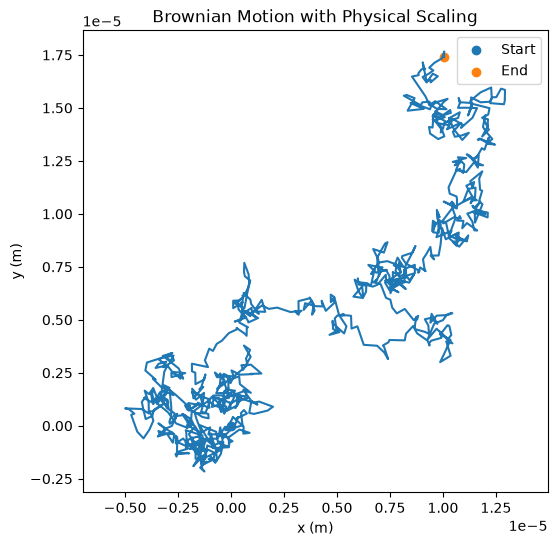

In [7]:
plt.figure(figsize=(6,6))

plt.plot(x, y)

plt.scatter(x[0], y[0], label="Start")

plt.scatter(x[-1], y[-1], label="End")

plt.axis("equal")

plt.xlabel("x (m)")
plt.ylabel("y (m)")

plt.title("Brownian Motion with Physical Scaling")

plt.legend()

plt.show()

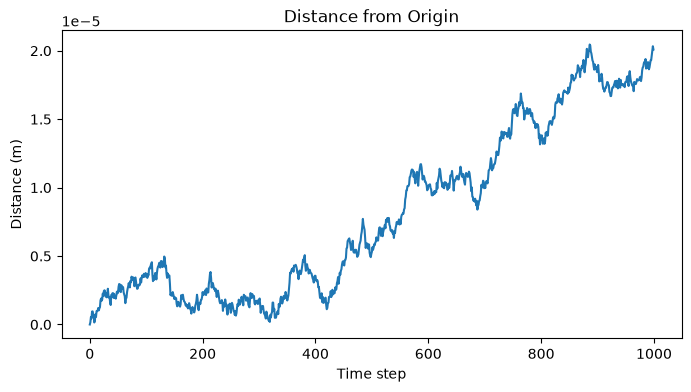

In [8]:
distance = np.sqrt(x**2 + y**2)

plt.figure(figsize=(8,4))

plt.plot(distance)

plt.xlabel("Time step")

plt.ylabel("Distance (m)")

plt.title("Distance from Origin")

plt.show()